# 08 — Backtest 003.1: Bollinger lateral segurando a posição, com swap (EURUSD H4 · H1)

**De onde vem:** no 003, zerar no fim do dia cortou metade das operações do H1 antes de o preço voltar ao meio
da banda, e o H4 deu a única pista positiva (sem filtro: 200 operações, +0,09 R fora da amostra). Só que o H4
segurava a posição de um dia para o outro **sem pagar swap**. Este teste corrige isso.

**O que muda em relação ao 003:**

| Item | 003 | 003.1 |
|---|---|---|
| Tempos gráficos | H4, H1, M15 | **H4 e H1** (o M15 sai em poucas barras e quase não pega swap) |
| Zerar no fim do dia | sim/não, sem swap | **segurar até o alvo ou o stop, pagando swap** (zerar fica como comparação) |
| Swap | não modelado | **swap real da XM por noite**, triplo na quarta-feira |
| Régua de lateralidade | inclinação da média de 200 | inclinação da média de 200 **ou ADX < 20** |

**Decisão tomada antes de ver os resultados:** segurar a posição durante a noite faz deste um setup de
*swing*, não de day trade. Por isso o critério de frequência de day trade aparece no veredito, mas **não elimina**.
Os outros cinco critérios continuam iguais.

> Sem look-ahead: o sinal usa a barra **fechada** e a entrada é na abertura da barra seguinte.

## 1. Configuração

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit

# ---------------- setup ----------------
BACKTEST_ID = "003.1"
SIMBOLO = "EURUSD"
TFS = ["H4", "H1"]
DATA_INICIO = "2010-01-01"

BB_PERIODO, BB_DESVIOS = 21, 2.0
MEDIA_LONGA = 200
LATERAL_BARRAS = 20
ATR_PERIODO = 14
ADX_PERIODO, ADX_LATERAL = 14, 20

# ---------------- grade (testada só no treino) ----------------
GRADE_GATILHO = ["fechou fora", "voltou para dentro"]
GRADE_LATERAL = ["sem filtro", "incl<1.0", "incl<0.5", "incl<0.25", "ADX<20"]
GRADE_STOP = [1.5, 2.0, 3.0]
GRADE_ZERAR = [False, True]  # False = segura e paga swap

# ---------------- sessão ----------------
SESSAO = (9, 21)  # hora de FECHAMENTO da barra de sinal (servidor XM)
HORA_ZERAR = 23
MULT_SPREAD_VIRADA = 1.5

# ---------------- custos e risco ----------------
SLIPPAGE_PONTOS = 2
COMISSAO_USD_LOTE = 0.0
RISCO_POR_TRADE = 0.01
# swap em pontos por noite (último valor gravado pela rotina de dados); triplo na quarta
MULT_SWAP = 1.0

# ---------------- validação ----------------
INICIO_OOS = {"H4": "2021-01-01", "H1": "2021-01-01"}
MIN_TRADES_TREINO = 60
N_SIM, SEED = 300, 42

RAIZ = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dados" / "xm").is_dir()), None)
if RAIZ is None:
    raise FileNotFoundError(f"Não encontrei a pasta dados/xm a partir de {Path.cwd()}")
PASTA_DADOS = RAIZ / "dados" / "xm"
sys.path.insert(0, str(RAIZ / "src"))
from lhsquant.estilo import aplicar_estilo, CORES

aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
info = pd.read_parquet(PASTA_DADOS / "info_simbolos.parquet")
info = info[info["simbolo"] == SIMBOLO].sort_values("data").iloc[-1]
PONTO, CONTRATO = float(info["ponto"]), float(info["contrato"])
SWAP_COMPRA, SWAP_VENDA = float(info["swap_compra"]), float(info["swap_venda"])
SLIP = SLIPPAGE_PONTOS * PONTO
print(f"{SIMBOLO}: swap compra {SWAP_COMPRA:+.2f} pontos/noite | venda {SWAP_VENDA:+.2f} (valores de {info['data']}) | "
      f"triplo na quarta | OOS a partir de 2021")

EURUSD: swap compra -7.48 pontos/noite | venda +1.23 (valores de 2026-10-20 00:00:00) | triplo na quarta | OOS a partir de 2021


### Como o swap entra na conta

- A cada virada de dia útil (meia-noite do servidor) com posição aberta, paga-se (ou recebe-se) o swap.
- Na **quarta para quinta** o swap é **triplo**, porque cobre o fim de semana.
- Hoje a XM **cobra** 7,48 pontos por noite na compra e **paga** 1,23 na venda (os juros do dólar estão acima
  dos do euro).
- **Limitação:** usamos o swap de hoje para todo o histórico. Entre 2010 e 2014 os juros do euro estavam acima
  dos do dólar e o sinal era o inverso. Por isso a seção 8 testa cenários de swap mais pesados.

## 2. Dados e indicadores (sem look-ahead)

In [2]:
DUR_H = {"H4": 4, "H1": 1}
HORAS_VIRADA = {"H4": (20, 0), "H1": (22, 23, 0)}


def calc_atr(df, n=ATR_PERIODO):
    h, l, c = df["maxima"], df["minima"], df["fechamento"]
    tr = pd.concat([h - l, (h - c.shift()).abs(), (l - c.shift()).abs()], axis=1).max(axis=1)
    return tr.ewm(alpha=1 / n, adjust=False).mean()


def calc_adx(df, n=ADX_PERIODO):
    alta, baixa = df["maxima"].diff(), -df["minima"].diff()
    dm_mais = pd.Series(np.where((alta > baixa) & (alta > 0), alta, 0.0), df.index)
    dm_menos = pd.Series(np.where((baixa > alta) & (baixa > 0), baixa, 0.0), df.index)
    atr = calc_atr(df, n)
    di_mais = 100 * dm_mais.ewm(alpha=1 / n, adjust=False).mean() / atr
    di_menos = 100 * dm_menos.ewm(alpha=1 / n, adjust=False).mean() / atr
    dx = 100 * (di_mais - di_menos).abs() / (di_mais + di_menos)
    return dx.ewm(alpha=1 / n, adjust=False).mean()


def preparar(tf):
    df = pd.read_parquet(PASTA_DADOS / SIMBOLO / f"{tf}.parquet").sort_index().loc[DATA_INICIO:]
    c = df["fechamento"]
    meio = c.rolling(BB_PERIODO).mean()
    dp = c.rolling(BB_PERIODO).std(ddof=0)
    longa = c.rolling(MEDIA_LONGA).mean()
    atr = calc_atr(df)
    idx = df.index
    fecha = idx + pd.Timedelta(hours=DUR_H[tf])
    dia = idx.normalize()
    ultimo_do_dia = np.append(dia[1:] != dia[:-1], True)
    mult = np.where(np.isin(idx.hour, HORAS_VIRADA[tf]), MULT_SPREAD_VIRADA, 1.0)
    return {
        "idx": idx,
        "o": df["abertura"].to_numpy(float), "h": df["maxima"].to_numpy(float),
        "l": df["minima"].to_numpy(float), "c": c.to_numpy(float),
        "spr": df["spread"].to_numpy(float) * PONTO * mult,
        "atr": atr.to_numpy(float),
        "meio": meio.to_numpy(float),
        "inf": (meio - BB_DESVIOS * dp).to_numpy(float),
        "sup": (meio + BB_DESVIOS * dp).to_numpy(float),
        "incl": ((longa - longa.shift(LATERAL_BARRAS)).abs() / atr).to_numpy(float),
        "adx": calc_adx(df).to_numpy(float),
        "pode": np.asarray((fecha.hour >= SESSAO[0]) & (fecha.hour < SESSAO[1])),
        "zerar_dia": np.asarray((fecha.hour >= HORA_ZERAR) | ultimo_do_dia),
        "fim_dados": np.append(np.zeros(len(idx) - 1, bool), True),
    }


def lateral(a, regra):
    # máscara de "mercado lateral" na barra fechada
    ok = ~np.isnan(a["incl"]) & ~np.isnan(a["inf"])
    if regra == "sem filtro":
        return ok
    if regra.startswith("incl<"):
        return ok & (a["incl"] < float(regra[5:]))
    return ok & (a["adx"] < ADX_LATERAL)


D = {tf: preparar(tf) for tf in TFS}
for tf, a in D.items():
    print(f"{tf}: {len(a['idx']):>7,} barras | {a['idx'][0]:%Y-%m-%d} → {a['idx'][-1]:%Y-%m-%d} | tempo lateral: " +
          " · ".join(f"{r} {lateral(a, r).mean():.0%}" for r in GRADE_LATERAL[1:]))

H4:  26,132 barras | 2010-01-04 → 2026-10-20 | tempo lateral: incl<1.0 70% · incl<0.5 39% · incl<0.25 19% · ADX<20 31%
H1: 100,066 barras | 2010-09-02 → 2026-10-21 | tempo lateral: incl<1.0 67% · incl<0.5 38% · incl<0.25 20% · ADX<20 31%


## 3. Sinais (iguais ao 003)

In [3]:
def sinais(a, gatilho, regra):
    c, inf, sup = a["c"], a["inf"], a["sup"]
    if gatilho == "fechou fora":
        compra, venda = c < inf, c > sup
    else:
        c1, inf1, sup1 = np.roll(c, 1), np.roll(inf, 1), np.roll(sup, 1)
        compra = (c1 < inf1) & (c >= inf) & (c < a["meio"])
        venda = (c1 > sup1) & (c <= sup) & (c > a["meio"])
        compra[0] = venda[0] = False
    ok = lateral(a, regra)
    return np.where(ok & compra, 1, np.where(ok & venda, -1, 0)).astype(np.int64)

## 4. O motor + o swap

O motor é o mesmo do 003, agora devolvendo também o **risco** de cada operação (para converter o swap em R).
Depois do motor, contamos as noites de cada operação:

- **noites** = dias úteis entre a data de entrada e a de saída (sexta → segunda conta 1 noite);
- **quartas** atravessadas valem 3 noites;
- **swap em R** = noites × swap (pontos) × ponto ÷ risco.

O resultado líquido passa a ser: preço − spread − slippage − comissão **+ swap**.

In [4]:
@njit(cache=True)
def motor(o, h, l, c, spr, atr, meio, sinal, pode, zerar, stop_atr, slip, comis):
    n = len(c)
    cap = n // 2 + 10
    ent = np.empty(cap, np.int64)
    sai = np.empty(cap, np.int64)
    dire = np.empty(cap, np.int64)
    mot = np.empty(cap, np.int64)
    rl = np.empty(cap)
    rb = np.empty(cap)
    rk = np.empty(cap)
    nt, pos = 0, 0
    stop, e_l, e_b, risco = 0.0, 0.0, 0.0, 1.0
    for t in range(1, n):
        if pos != 0:
            px, m = 0.0, 0
            if pos == 1 and l[t] <= stop:
                px, m = min(o[t], stop), 1
            elif pos == -1 and h[t] + spr[t] >= stop:
                px, m = max(o[t] + spr[t], stop), 1
            if m == 0:
                if (pos == 1 and c[t] >= meio[t]) or (pos == -1 and c[t] <= meio[t]):
                    m = 2
                elif zerar[t]:
                    m = 3
                elif t == n - 1:
                    m = 4
                if m != 0:
                    px = c[t] if pos == 1 else c[t] + spr[t]
            if m != 0:
                if pos == 1:
                    x_b, x_l = px, px - slip
                else:
                    x_b, x_l = px - spr[t], px + slip
                rb[nt] = pos * (x_b - e_b) / risco
                rl[nt] = (pos * (x_l - e_l) - comis) / risco
                rk[nt] = risco
                sai[nt], mot[nt] = t, m
                nt += 1
                pos = 0
            continue
        if sinal[t] == 0 or not pode[t] or zerar[t] or t + 1 >= n:
            continue
        d, j = sinal[t], t + 1
        if (d == 1 and o[j] >= meio[t]) or (d == -1 and o[j] <= meio[t]):
            continue
        e_b = o[j]
        if d == 1:
            e_l = o[j] + spr[j] + slip
            stop = e_l - stop_atr * atr[t]
        else:
            e_l = o[j] - slip
            stop = e_l + stop_atr * atr[t]
        risco = abs(e_l - stop)
        pos = d
        ent[nt], dire[nt] = j, d
    return ent[:nt], sai[:nt], dire[:nt], mot[:nt], rl[:nt], rb[:nt], rk[:nt]


MOTIVOS = np.array(["", "stop", "meio da banda", "fim do dia", "fim dos dados"])


def rodar(tf, gatilho, regra, stop_atr, zerar, comissao=COMISSAO_USD_LOTE, sinal=None,
          swap=None, mult_swap=MULT_SWAP):
    a = D[tf]
    s = sinais(a, gatilho, regra) if sinal is None else sinal
    z = a["zerar_dia"] if zerar else a["fim_dados"]
    ent, sai, d, m, rl, rb, rk = motor(a["o"], a["h"], a["l"], a["c"], a["spr"], a["atr"], a["meio"],
                                       s, a["pode"], z, float(stop_atr), SLIP, comissao / CONTRATO)
    tr = pd.DataFrame({"entrada": a["idx"][ent], "saida": a["idx"][sai], "direcao": d,
                       "motivo": MOTIVOS[m], "R_sem_swap": rl, "R_bruto": rb, "risco": rk,
                       "barras": sai - ent + 1})
    d_ent = tr["entrada"].dt.normalize().to_numpy().astype("datetime64[D]")
    d_sai = tr["saida"].dt.normalize().to_numpy().astype("datetime64[D]")
    noites = np.busday_count(d_ent, d_sai) + 2 * np.busday_count(d_ent, d_sai, weekmask="0010000")
    sw_c, sw_v = swap or (SWAP_COMPRA, SWAP_VENDA)
    pontos = np.where(tr["direcao"] == 1, sw_c, sw_v) * mult_swap
    tr["noites"] = noites
    tr["R_swap"] = noites * pontos * PONTO / tr["risco"]
    tr["R"] = tr["R_sem_swap"] + tr["R_swap"]
    return tr

### Métricas (iguais ao 003, mais o efeito do swap)

In [5]:
def frequencia(tr, ini, fim):
    dias = pd.bdate_range(ini.normalize(), fim.normalize())
    d_ent = np.sort(tr["entrada"].dt.normalize().unique().to_numpy().astype("datetime64[D]"))
    pontos = np.concatenate([[np.datetime64(ini.normalize(), "D")], d_ent, [np.datetime64(fim.normalize(), "D")]])
    gaps = np.busday_count(pontos[:-1], pontos[1:])
    gaps = gaps[gaps > 0] if (gaps > 0).any() else np.array([len(dias)])
    return {"Trades/semana": len(tr) / (len(dias) / 5),
            "Intervalo p90 (dias úteis)": float(np.percentile(gaps, 90))}


def metricas(tr, ini, fim):
    tr = tr[(tr["entrada"] >= ini) & (tr["entrada"] <= fim)]
    if len(tr) == 0:
        return pd.Series({"Nº trades": 0})
    r = tr["R"]
    g, p = r[r > 0], r[r <= 0]
    cap = (1 + RISCO_POR_TRADE * r).cumprod()
    dias = pd.bdate_range(ini.normalize(), fim.normalize())
    ret_d = (tr.groupby(tr["saida"].dt.normalize())["R"].sum() * RISCO_POR_TRADE).reindex(dias, fill_value=0.0)
    neg = np.minimum(ret_d, 0)
    return pd.Series({
        "Nº trades": len(tr),
        "Win rate %": len(g) / len(tr) * 100,
        "Payoff": g.mean() / abs(p.mean()) if len(p) and len(g) else np.nan,
        "Expectativa R sem custos": tr["R_bruto"].mean(),
        "Expectativa R sem swap": tr["R_sem_swap"].mean(),
        "Swap médio R": tr["R_swap"].mean(),
        "Expectativa R": r.mean(),
        "Fator de lucro": g.sum() / abs(p.sum()) if len(p) else np.nan,
        "Retorno % (1% risco)": (cap.iloc[-1] - 1) * 100,
        "Máx. drawdown %": (cap / cap.cummax() - 1).min() * 100,
        "Sharpe": ret_d.mean() / ret_d.std() * np.sqrt(252) if ret_d.std() > 0 else np.nan,
        "Sortino": ret_d.mean() / np.sqrt((neg ** 2).mean()) * np.sqrt(252) if (neg < 0).any() else np.nan,
        "Noites médias": tr["noites"].mean(),
        **frequencia(tr, ini, fim),
    })


def dd_ano(r):
    cap = (1 + RISCO_POR_TRADE * r).cumprod()
    return (cap / cap.cummax() - 1).min() * 100


def periodos(tf):
    a = D[tf]
    oos = pd.Timestamp(INICIO_OOS[tf])
    return {"treino": (a["idx"][0], oos - pd.Timedelta(seconds=1)), "fora": (oos, a["idx"][-1])}

## 5. A pista do 003, agora com swap

A configuração que chamou atenção no 003 (H4, **voltou para dentro**, **sem filtro**, stop 1,5 ATR, segurando
a posição) e a regra padrão do 003 segurando a posição. Comparamos: sem swap × com swap.

In [6]:
casos = {
    "Pista do 003 (H4)": ("H4", dict(gatilho="voltou para dentro", regra="sem filtro", stop_atr=1.5, zerar=False)),
    "Padrão segurando (H4)": ("H4", dict(gatilho="fechou fora", regra="incl<0.5", stop_atr=3.0, zerar=False)),
    "Padrão segurando (H1)": ("H1", dict(gatilho="fechou fora", regra="incl<0.5", stop_atr=3.0, zerar=False)),
}
linhas = {}
for nome, (tf, cfg) in casos.items():
    tr = rodar(tf, **cfg)
    for per, (ini, fim) in periodos(tf).items():
        linhas[(nome, per)] = metricas(tr, ini, fim)
RES_PISTA = pd.DataFrame(linhas)
display(RES_PISTA.loc[["Nº trades", "Win rate %", "Expectativa R sem custos", "Expectativa R sem swap", "Swap médio R",
                       "Expectativa R", "Fator de lucro", "Máx. drawdown %", "Noites médias"]].round(3))

Pista do 003 (H4)         Padrão segurando (H4)  \
                                    treino    fora                treino   
Nº trades                          366.000 200.000               260.000   
Win rate %                          53.005  56.500                51.154   
Expectativa R sem custos             0.049   0.150                -0.081   
Expectativa R sem swap               0.013   0.090                -0.100   
Swap médio R                        -0.008  -0.011                -0.009   
Expectativa R                        0.005   0.079                -0.109   
Fator de lucro                       1.010   1.181                 0.710   
Máx. drawdown %                    -20.204 -10.685               -26.248   
Noites médias                        1.478   1.535                 2.731   

                                 Padrão segurando (H1)          
                            fora                treino    fora  
Nº trades                124.000             1,112.000 633.000  
Win rate %                58.871                56.835  59.242  
Expectativa R sem custos   0.027                -0.016   0.061  
Expectativa R sem swap    -0.003                -0.052   0.008  
Swap médio R              -0.013                -0.005  -0.006  
Expectativa R             -0.016                -0.057   0.003  
Fator de lucro             0.954                 0.837   1.008  
Máx. drawdown %           -9.963               -51.956 -20.909  
Noites médias              2.532                 0.730   0.746

**Como ler:** "Expectativa R sem swap" é o resultado com spread e slippage, como no 003. "Swap médio R" é o quanto
o swap soma (positivo) ou tira (negativo) por operação. "Expectativa R" é o líquido final.

## 6. Grade de variações (só no treino)

60 combinações por tempo gráfico: 2 gatilhos × 5 réguas de lateralidade (incluindo **sem filtro** e **ADX < 20**)
× 3 stops × segurar/zerar. A melhor é escolhida **só pelo treino** (maior expectativa líquida, já com swap, e
pelo menos 60 operações).

In [7]:
grade = []
for tf in TFS:
    (ti, tfim), (oi, ofim) = periodos(tf).values()
    for g in GRADE_GATILHO:
        for regra in GRADE_LATERAL:
            for st in GRADE_STOP:
                for z in GRADE_ZERAR:
                    tr = rodar(tf, g, regra, st, z)
                    mt, mo = metricas(tr, ti, tfim), metricas(tr, oi, ofim)
                    grade.append({"tf": tf, "gatilho": g, "regra": regra, "stop_atr": st, "zerar": z,
                                  "trades_treino": mt.get("Nº trades", 0), "exp_treino": mt.get("Expectativa R", np.nan),
                                  "swap_treino": mt.get("Swap médio R", np.nan),
                                  "trades_fora": mo.get("Nº trades", 0), "exp_fora": mo.get("Expectativa R", np.nan)})
GRADE = pd.DataFrame(grade)

ESCOLHA = {}
for tf in TFS:
    g = GRADE[(GRADE["tf"] == tf) & (GRADE["trades_treino"] >= MIN_TRADES_TREINO)]
    melhor = g.sort_values("exp_treino", ascending=False).iloc[0]
    ESCOLHA[tf] = {"gatilho": melhor["gatilho"], "regra": melhor["regra"],
                   "stop_atr": float(melhor["stop_atr"]), "zerar": bool(melhor["zerar"])}
    print(f"\n{tf}: {len(g)} combinações válidas | positivas no treino: {(g['exp_treino'] > 0).sum()} | "
          f"positivas fora (só para conferência): {(g['exp_fora'] > 0).sum()}")
    display(g.sort_values("exp_treino", ascending=False).head(5).drop(columns="tf").round(3).reset_index(drop=True))
    por_regra = g.groupby("regra")[["exp_treino", "exp_fora"]].mean().sort_values("exp_treino", ascending=False)
    print("Média por régua de lateralidade:")
    display(por_regra.round(3))


H4: 60 combinações válidas | positivas no treino: 25 | positivas fora (só para conferência): 25


,gatilho,regra,stop_atr,zerar,trades_treino,exp_treino,swap_treino,trades_fora,exp_fora
0,voltou para dentro,ADX<20,3.000,False,91.000,0.080,-0.007,51.000,-0.114
1,voltou para dentro,ADX<20,1.500,False,95.000,0.054,-0.006,52.000,-0.054
2,voltou para dentro,incl<0.25,1.500,False,83.000,0.054,-0.007,36.000,0.090
3,voltou para dentro,incl<0.5,1.500,False,147.000,0.034,-0.009,75.000,0.196
4,voltou para dentro,incl<0.5,2.000,True,144.000,0.032,0.000,78.000,0.057


Média por régua de lateralidade:


,exp_treino,exp_fora
regra,,
ADX<20,0.005,-0.042
incl<0.25,-0.027,0.028
incl<1.0,-0.046,0.012
incl<0.5,-0.047,0.034
sem filtro,-0.052,0.003



H1: 60 combinações válidas | positivas no treino: 0 | positivas fora (só para conferência): 4


,gatilho,regra,stop_atr,zerar,trades_treino,exp_treino,swap_treino,trades_fora,exp_fora
0,voltou para dentro,incl<0.5,3.000,True,968.000,-0.013,0.000,517.000,-0.019
1,voltou para dentro,incl<1.0,3.000,True,"1,628.000",-0.014,0.000,901.000,-0.044
2,voltou para dentro,incl<1.0,3.000,False,"1,576.000",-0.019,-0.005,891.000,-0.029
3,voltou para dentro,sem filtro,3.000,False,"2,256.000",-0.020,-0.004,"1,246.000",-0.048
4,voltou para dentro,sem filtro,3.000,True,"2,330.000",-0.020,0.000,"1,266.000",-0.065


Média por régua de lateralidade:


,exp_treino,exp_fora
regra,,
sem filtro,-0.047,-0.072
incl<1.0,-0.050,-0.049
incl<0.5,-0.059,-0.026
incl<0.25,-0.075,-0.030
ADX<20,-0.076,-0.092


## 7. Fora da amostra e comparação com o acaso

A combinação escolhida no treino roda no período 2021–2026. O teste do acaso sorteia entradas no mesmo regime,
sempre apostando na volta à média, com as mesmas saídas, stop **e swap**.

H4: escolhida no treino → {'gatilho': 'voltou para dentro', 'regra': 'ADX<20', 'stop_atr': 3.0, 'zerar': False}


H1: escolhida no treino → {'gatilho': 'voltou para dentro', 'regra': 'incl<0.5', 'stop_atr': 3.0, 'zerar': True}


,H4,H1
Nº trades,51.000,517.000
Win rate %,54.902,52.611
Payoff,0.541,0.829
Expectativa R sem custos,-0.073,0.036
Expectativa R sem swap,-0.104,-0.019
Swap médio R,-0.009,0.000
Expectativa R,-0.114,-0.019
Fator de lucro,0.659,0.920
Retorno % (1% risco),-5.740,-10.350
Máx. drawdown %,-7.225,-20.497


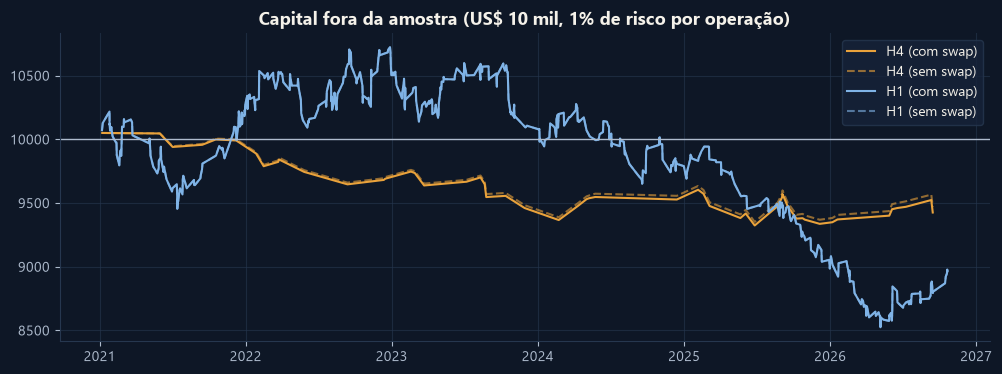


H4 — por lado e motivo de saída (fora da amostra):


R        R_swap       
                     count   mean  count   mean
lado   motivo                                  
compra meio da banda    21  0.254     21 -0.019
       stop              6 -1.029      6 -0.026
venda  meio da banda    15  0.269     15  0.004
       stop              9 -0.999      9  0.003


H1 — por lado e motivo de saída (fora da amostra):


R        R_swap      
                     count   mean  count  mean
lado   motivo                                 
compra fim do dia      141 -0.125    141 0.000
       meio da banda    94  0.534     94 0.000
       stop             33 -1.006     33 0.000
venda  fim do dia      128 -0.125    128 0.000
       meio da banda    82  0.559     82 0.000
       stop             39 -1.006     39 0.000

In [8]:
def aleatorio(tf, cfg, n_alvo, ini, fim, rng):
    a = D[tf]
    ok = a["pode"] & lateral(a, cfg["regra"]) & (a["idx"] >= ini) & (a["idx"] <= fim)
    elegiveis = np.flatnonzero(ok)
    s = np.zeros(len(a["c"]), np.int64)
    escolhidas = rng.choice(elegiveis, size=min(len(elegiveis), n_alvo * 3), replace=False)
    s[escolhidas] = np.where(a["c"][escolhidas] < a["meio"][escolhidas], 1, -1)
    return rodar(tf, sinal=s, **cfg)


rng = np.random.default_rng(SEED)
OOS, TR_OOS, P_VALOR = {}, {}, {}
for tf in TFS:
    oi, ofim = periodos(tf)["fora"]
    cfg = ESCOLHA[tf]
    tr = rodar(tf, **cfg)
    TR_OOS[tf] = tr[tr["entrada"] >= oi]
    m = metricas(tr, oi, ofim)
    sims = np.array([np.nanmean(aleatorio(tf, cfg, int(m["Nº trades"]), oi, ofim, rng)["R"]) for _ in range(N_SIM)])
    P_VALOR[tf] = float(np.nanmean(sims >= m["Expectativa R"]))
    m["Aleatório: expectativa R"] = np.nanmean(sims)
    m["p-valor vs aleatório"] = P_VALOR[tf]
    m["Com comissão US$7: expectativa R"] = metricas(rodar(tf, comissao=7.0, **cfg), oi, ofim)["Expectativa R"]
    OOS[tf] = m
    print(f"{tf}: escolhida no treino → {cfg}")
RES_OOS = pd.DataFrame(OOS)
display(RES_OOS.round(3))

fig, ax = plt.subplots(figsize=(12, 4))
for tf, cor in zip(TFS, [CORES["primaria"], CORES["secundaria"]]):
    t_ = TR_OOS[tf].sort_values("saida")
    ax.plot(t_["saida"], 10_000 * (1 + RISCO_POR_TRADE * t_["R"]).cumprod(), color=cor, label=f"{tf} (com swap)")
    ax.plot(t_["saida"], 10_000 * (1 + RISCO_POR_TRADE * t_["R_sem_swap"]).cumprod(), color=cor, ls="--", alpha=0.6,
            label=f"{tf} (sem swap)")
ax.axhline(10_000, color=CORES["texto_suave"], lw=1)
ax.set_title("Capital fora da amostra (US$ 10 mil, 1% de risco por operação)")
ax.legend()
plt.show()

for tf in TFS:
    t_ = TR_OOS[tf].assign(lado=np.where(TR_OOS[tf]["direcao"] == 1, "compra", "venda"))
    q = t_.groupby(["lado", "motivo"])[["R", "R_swap"]].agg(["count", "mean"]).round(3)
    print(f"\n{tf} — por lado e motivo de saída (fora da amostra):")
    display(q)

## 8. Sensibilidade ao swap

O swap muda com os juros. Testamos a configuração escolhida (fora da amostra) com:
- **sem swap** (como no 003);
- **swap de hoje**;
- **swap em dobro**;
- **conservador:** os dois lados pagando 7,48 pontos por noite (como se a venda também cobrasse).

In [9]:
cenarios = {"sem swap": ((SWAP_COMPRA, SWAP_VENDA), 0.0), "swap de hoje": ((SWAP_COMPRA, SWAP_VENDA), 1.0),
            "swap em dobro": ((SWAP_COMPRA, SWAP_VENDA), 2.0),
            "conservador": ((-abs(SWAP_COMPRA), -abs(SWAP_COMPRA)), 1.0)}
sens = {}
for tf in TFS:
    oi, ofim = periodos(tf)["fora"]
    for nome, (sw, mult) in cenarios.items():
        m = metricas(rodar(tf, swap=sw, mult_swap=mult, **ESCOLHA[tf]), oi, ofim)
        sens[(tf, nome)] = m[["Expectativa R", "Fator de lucro", "Máx. drawdown %"]]
display(pd.DataFrame(sens).round(3))

H4                                              H1  \
                sem swap swap de hoje swap em dobro conservador sem swap   
Expectativa R     -0.104       -0.114        -0.123      -0.125   -0.019   
Fator de lucro     0.682        0.659         0.636       0.631    0.920   
Máx. drawdown %   -6.945       -7.225        -7.504      -7.564  -20.497   

                                                        
                swap de hoje swap em dobro conservador  
Expectativa R         -0.019        -0.019      -0.019  
Fator de lucro         0.920         0.920       0.920  
Máx. drawdown %      -20.497       -20.497     -20.497

## 9. Veredito

Critérios aplicados ao melhor tempo gráfico fora da amostra. Como decidido no início, a frequência de day trade
é **informativa** (este setup segura a posição durante a noite).

In [10]:
MELHOR_TF = max(TFS, key=lambda tf: OOS[tf]["Expectativa R"])
m = OOS[MELHOR_TF]
dd_anos = TR_OOS[MELHOR_TF].groupby(TR_OOS[MELHOR_TF]["entrada"].dt.year)["R"].apply(dd_ano)
conserv = sens[(MELHOR_TF, "conservador")]["Expectativa R"]
criterios = pd.DataFrame([
    ("≥ 100 operações fora da amostra", f"{m['Nº trades']:.0f}", m["Nº trades"] >= 100, "sim"),
    ("Expectativa > 0 R (líquida, com swap)", f"{m['Expectativa R']:+.3f}", m["Expectativa R"] > 0, "sim"),
    ("Fator de lucro > 1,2", f"{m['Fator de lucro']:.2f}", m["Fator de lucro"] > 1.2, "sim"),
    ("Melhor que aleatório (p < 0,05)", f"p = {P_VALOR[MELHOR_TF]:.3f}", P_VALOR[MELHOR_TF] < 0.05, "sim"),
    ("Nenhum ano com DD > 20%", f"pior {dd_anos.min():.1f}%", dd_anos.min() > -20, "sim"),
    ("Frequência de day trade (≥ 2/semana)", f"{m['Trades/semana']:.1f}/sem", m["Trades/semana"] >= 2, "informativo"),
    ("Positivo no swap conservador", f"{conserv:+.3f}", conserv > 0, "informativo"),
], columns=["Critério", "Valor", "Passou", "Elimina?"])
criterios["Passou"] = criterios["Passou"].map({True: "✅", False: "❌"})
print(f"Melhor tempo gráfico fora da amostra: {MELHOR_TF} | configuração: {ESCOLHA[MELHOR_TF]}")
display(criterios)
elim = criterios[criterios["Elimina?"] == "sim"]
APROVADO = (elim["Passou"] == "✅").all()
print("VEREDITO:", "✅ APROVADO" if APROVADO else
      f"❌ REPROVADO ({(elim['Passou'] == '❌').sum()} de {len(elim)} critérios eliminatórios falharam)")

Melhor tempo gráfico fora da amostra: H1 | configuração: {'gatilho': 'voltou para dentro', 'regra': 'incl<0.5', 'stop_atr': 3.0, 'zerar': True}


,Critério,Valor,Passou,Elimina?
0,≥ 100 operações fora da amostra,517,✅,sim
1,"Expectativa > 0 R (líquida, com swap)",-0.019,❌,sim
2,"Fator de lucro > 1,2",0.92,❌,sim
3,"Melhor que aleatório (p < 0,05)",p = 0.093,❌,sim
4,Nenhum ano com DD > 20%,pior -9.6%,✅,sim
5,Frequência de day trade (≥ 2/semana),1.7/sem,❌,informativo
6,Positivo no swap conservador,-0.019,❌,informativo


VEREDITO: ❌ REPROVADO (3 de 5 critérios eliminatórios falharam)


## 10. Salvar os resultados
Tudo vai para `backtests/003.1_bollinger_swap_EURUSD_H4-H1/`.

In [11]:
PASTA_BT = RAIZ / "backtests" / "003.1_bollinger_swap_EURUSD_H4-H1"
PASTA_BT.mkdir(parents=True, exist_ok=True)
params = {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, list, dict, tuple, type(None)))
          and k not in ("D", "OOS", "TR_OOS", "P_VALOR")}
(PASTA_BT / "parametros.json").write_text(json.dumps(params, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
RES_PISTA.to_csv(PASTA_BT / "metricas_pista.csv")
RES_OOS.to_csv(PASTA_BT / "metricas_oos.csv")
GRADE.to_csv(PASTA_BT / "grade_otimizacao.csv", index=False)
pd.DataFrame(sens).to_csv(PASTA_BT / "sensibilidade_swap.csv")
criterios.to_csv(PASTA_BT / "criterios.csv", index=False)
pd.concat([t.assign(tf=tf) for tf, t in TR_OOS.items()]).to_csv(PASTA_BT / "operacoes_oos.csv", index=False)
print(f"Salvo em {PASTA_BT}")

Salvo em C:\Dev\GitHub\LHS Capital\lhs-quant-lab\backtests\003.1_bollinger_swap_EURUSD_H4-H1


## 11. Conclusões

**Veredito: ❌ reprovado (3 de 5 critérios eliminatórios).** O que os números mostraram:

1. **O swap não era o problema.** Ele custa só cerca de **−0,01 R por operação**: as operações duram em média 1,5 a
   2,7 noites e o stop em ATR é largo no H4. Nem com o swap em dobro, nem no cenário conservador, o resultado muda de sinal.
2. **A pista do 003 não se sustenta.** Com swap, ela continua positiva fora da amostra (+0,079 R, fator de lucro 1,18,
   200 operações), mas **no treino (2010–2020) foi praticamente zero** (+0,005 R em 366 operações). Um setup com vantagem
   real deveria aparecer nos dois períodos; o positivo de 2021–2026 parece mais o período do que o método.
3. **A otimização enganou, como era de esperar.** No H4, a melhor combinação do treino (ADX < 20, +0,08 R) foi a **pior fora
   da amostra** (−0,11 R, pior que o acaso, p = 0,99). As réguas que lideram no treino não lideram fora: ranking invertido.
4. **No H1, segurar a posição ajuda, mas não cria vantagem.** Sem zerar no fim do dia, a regra padrão vai de −0,03 R
   para **+0,003 R** fora da amostra (fator de lucro 1,01): corrige o problema das saídas antecipadas, mas fica no zero.
5. **Somando 003 e 003.1** (mais de 100 combinações em três tempos gráficos), a volta à média nas Bandas de Bollinger
   **não mostrou vantagem consistente no EURUSD depois dos custos**.

**Recomendação:** encerrar a família Bollinger e seguir para o **004 (rompimento da faixa asiática na abertura de Londres)**,
que testa a lógica oposta (rompimento em vez de volta à média).

## 12. Exercícios

1. Mude `MULT_SWAP` para 0 e rode tudo: quanto da diferença entre o 003 e o 003.1 vem só do swap?
2. Troque `ADX_LATERAL` para 25. A régua do ADX fica melhor ou pior que a da média de 200?
3. Restrinja o setup **só a vendas** (que recebem swap hoje). O resultado melhora? Por que isso seria perigoso
   de concluir com o swap de hoje aplicado a 2010–2014?